In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import seaborn as sns
from scipy.signal import spectrogram
import pandas as pd
import pywt

In [2]:
# Load the standing data
magnitude_data_90 = loadmat(r'Zakir_New_Dataset\1m\90_1m_Standing\Sample1\P01A\Data_amplitude.mat')["Data_amplitude"]
phase_data_90 = loadmat(r'Zakir_New_Dataset\1m\90_1m_Standing\Sample1\P01A\Data_phase.mat')["Data_phase"]

magnitude_data_minus90 = loadmat(r'Zakir_New_Dataset\1m\-90_1m_Standing\Sample1\P01A\Data_amplitude.mat')["Data_amplitude"]
phase_data_minus90 = loadmat(r'Zakir_New_Dataset\1m\-90_1m_Standing\Sample1\P01A\Data_phase.mat')["Data_phase"]

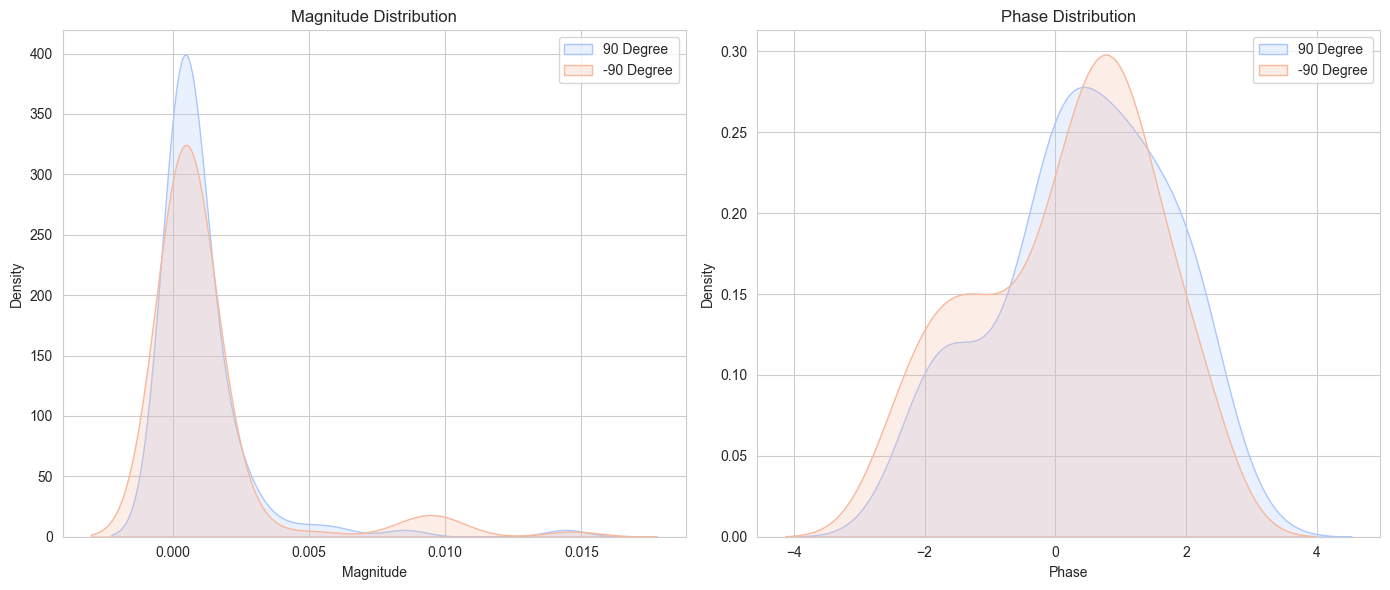

In [4]:
# Setting up a sophisticated color palette and style
sns.set_style("whitegrid")
colors = sns.color_palette("coolwarm", 2)

# Create subplots
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Plotting magnitude distribution
sns.kdeplot(np.mean(magnitude_data_90, axis=0), ax=ax[0], color=colors[0], label='90 Degree', shade=True)
sns.kdeplot(np.mean(magnitude_data_minus90, axis=0), ax=ax[0], color=colors[1], label='-90 Degree', shade=True)
ax[0].set_title('Magnitude Distribution')
ax[0].set_xlabel('Magnitude')
ax[0].set_ylabel('Density')
ax[0].legend()

# Plotting phase distribution
sns.kdeplot(np.mean(phase_data_90, axis=0), ax=ax[1], color=colors[0], label='90 Degree', shade=True)
sns.kdeplot(np.mean(phase_data_minus90, axis=0), ax=ax[1], color=colors[1], label='-90 Degree', shade=True)
ax[1].set_title('Phase Distribution')
ax[1].set_xlabel('Phase')
ax[1].set_ylabel('Density')
ax[1].legend()

plt.tight_layout()
plt.show()

D:\Softwares\Installed Softwares\Anaconda\lib\site-packages\pywt\_cwt.py:117: FutureWarning: Wavelets from the family cmor, without parameters specified in the name are deprecated. The name should takethe form cmorB-C where B and C are floats representing the bandwidth frequency and center frequency, respectively (example: cmor1.5-1.0).
  wavelet = DiscreteContinuousWavelet(wavelet)


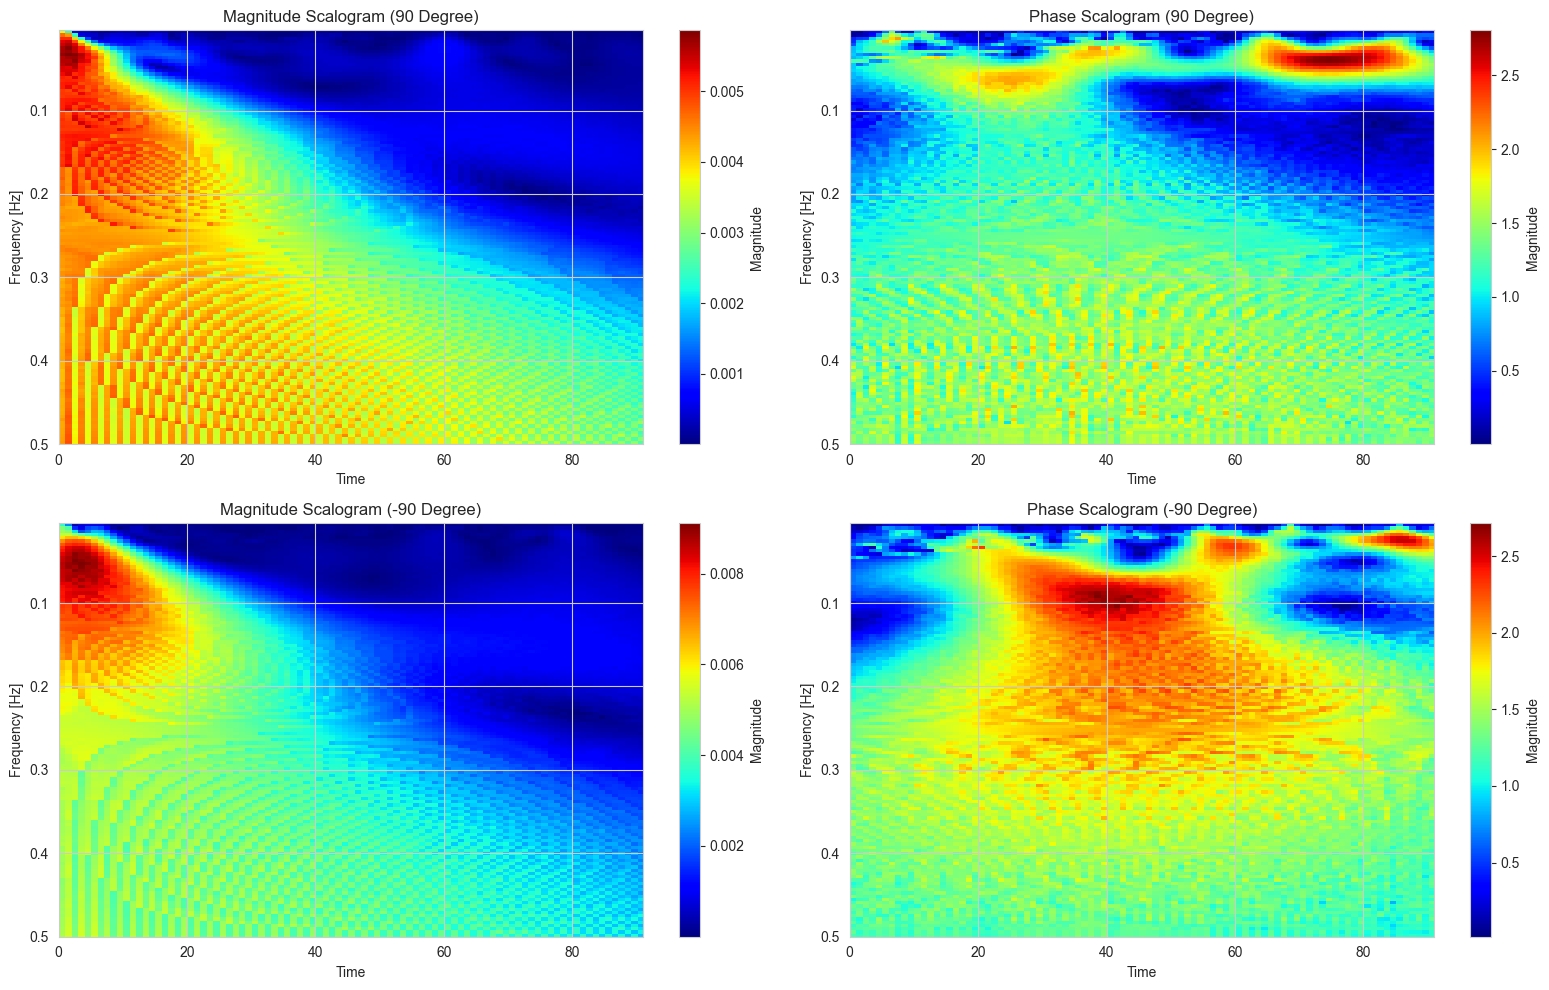

In [10]:
# Compute the mean across samples (if necessary)
magnitude_90_mean = np.mean(magnitude_data_90, axis=0)
phase_90_mean = np.mean(phase_data_90, axis=0)

magnitude_minus90_mean = np.mean(magnitude_data_minus90, axis=0)
phase_minus90_mean = np.mean(phase_data_minus90, axis=0)

# Continuous Wavelet Transform for magnitude and phase
coefficients_magnitude_90, frequencies_magnitude_90 = pywt.cwt(magnitude_90_mean, scales=np.arange(1, 128), wavelet='cmor')
coefficients_phase_90, frequencies_phase_90 = pywt.cwt(phase_90_mean, scales=np.arange(1, 128), wavelet='cmor')

coefficients_magnitude_minus90, frequencies_magnitude_minus90 = pywt.cwt(magnitude_minus90_mean, scales=np.arange(1, 128), wavelet='cmor')
coefficients_phase_minus90, frequencies_phase_minus90 = pywt.cwt(phase_minus90_mean, scales=np.arange(1, 128), wavelet='cmor')

# Plotting
plt.figure(figsize=(16, 10))

# 90 Degree Magnitude data
plt.subplot(2, 2, 1)
plt.imshow(np.abs(coefficients_magnitude_90), aspect='auto', cmap='jet', 
           extent=[0, len(magnitude_90_mean), frequencies_magnitude_90[0], frequencies_magnitude_90[-1]])
plt.colorbar(label='Magnitude')
plt.title('Magnitude Scalogram (90 Degree)')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time')

# 90 Degree Phase data
plt.subplot(2, 2, 2)
plt.imshow(np.abs(coefficients_phase_90), aspect='auto', cmap='jet', 
           extent=[0, len(phase_90_mean), frequencies_phase_90[0], frequencies_phase_90[-1]])
plt.colorbar(label='Magnitude')
plt.title('Phase Scalogram (90 Degree)')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time')

# -90 Degree Magnitude data
plt.subplot(2, 2, 3)
plt.imshow(np.abs(coefficients_magnitude_minus90), aspect='auto', cmap='jet', 
           extent=[0, len(magnitude_minus90_mean), frequencies_magnitude_minus90[0], frequencies_magnitude_minus90[-1]])
plt.colorbar(label='Magnitude')
plt.title('Magnitude Scalogram (-90 Degree)')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time')

# -90 Degree Phase data
plt.subplot(2, 2, 4)
plt.imshow(np.abs(coefficients_phase_minus90), aspect='auto', cmap='jet', 
           extent=[0, len(phase_minus90_mean), frequencies_phase_minus90[0], frequencies_phase_minus90[-1]])
plt.colorbar(label='Magnitude')
plt.title('Phase Scalogram (-90 Degree)')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time')

plt.tight_layout()
plt.show()


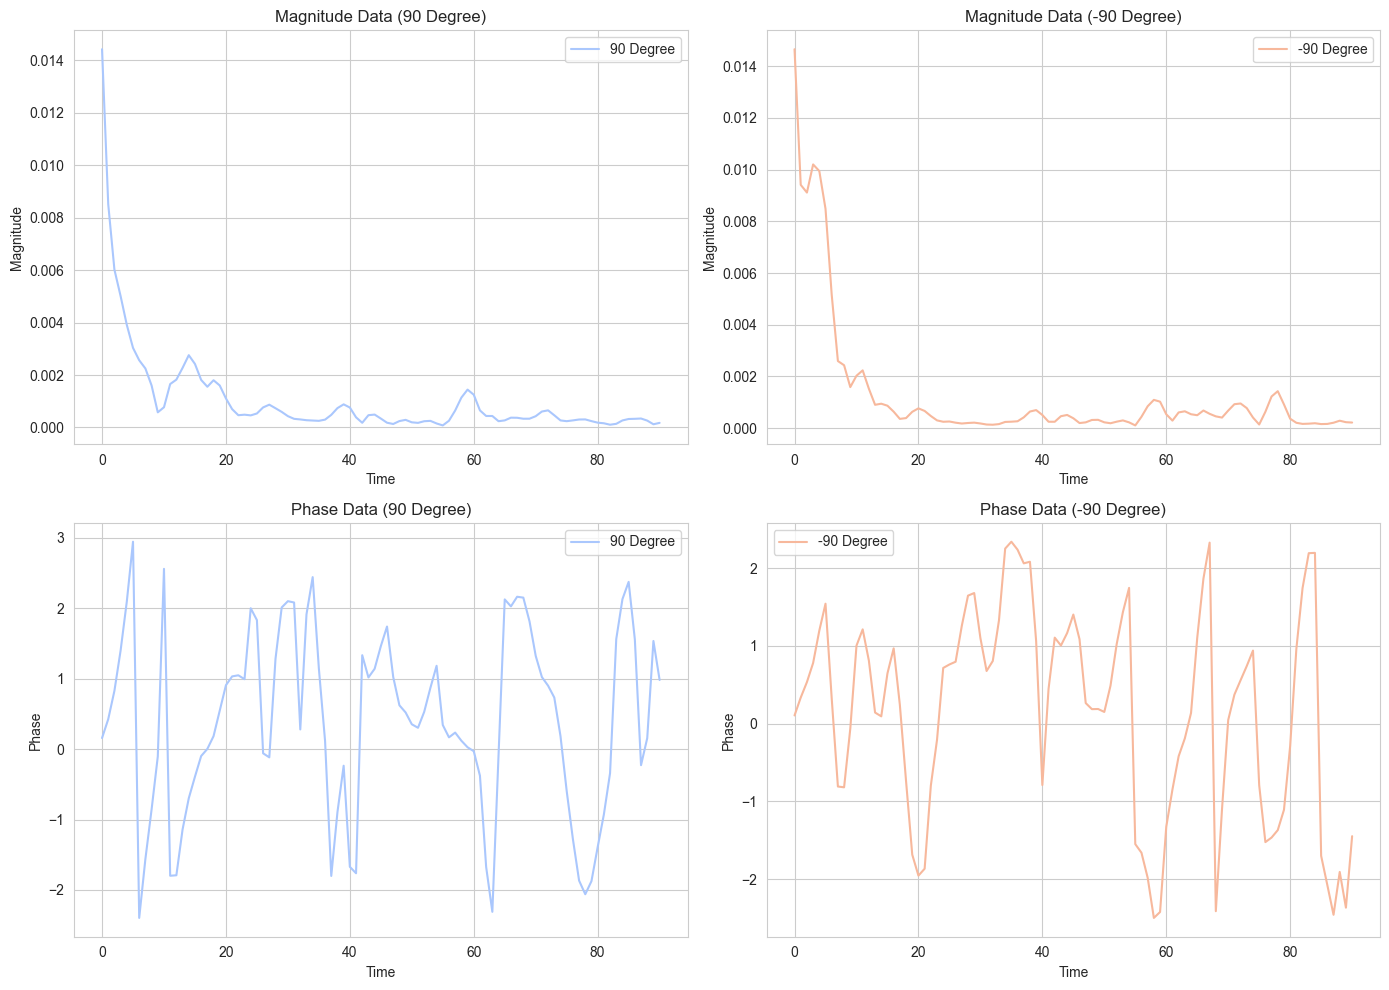

In [3]:
# Setting up a sophisticated color palette and style
sns.set_style("whitegrid")
colors = sns.color_palette("coolwarm", 2)

# Create subplots
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# Plotting magnitude data for 90 degree
ax[0, 0].plot(np.arange(magnitude_data_90.shape[1]), np.mean(magnitude_data_90, axis=0), color=colors[0], label='90 Degree')
ax[0, 0].set_title('Magnitude Data (90 Degree)')
ax[0, 0].set_xlabel('Time')
ax[0, 0].set_ylabel('Magnitude')
ax[0, 0].legend()

# Plotting phase data for 90 degree
ax[1, 0].plot(np.arange(phase_data_90.shape[1]), np.mean(phase_data_90, axis=0), color=colors[0], label='90 Degree')
ax[1, 0].set_title('Phase Data (90 Degree)')
ax[1, 0].set_xlabel('Time')
ax[1, 0].set_ylabel('Phase')
ax[1, 0].legend()

# Plotting magnitude data for -90 degree
ax[0, 1].plot(np.arange(magnitude_data_minus90.shape[1]), np.mean(magnitude_data_minus90, axis=0), color=colors[1], label='-90 Degree')
ax[0, 1].set_title('Magnitude Data (-90 Degree)')
ax[0, 1].set_xlabel('Time')
ax[0, 1].set_ylabel('Magnitude')
ax[0, 1].legend()

# Plotting phase data for -90 degree
ax[1, 1].plot(np.arange(phase_data_minus90.shape[1]), np.mean(phase_data_minus90, axis=0), color=colors[1], label='-90 Degree')
ax[1, 1].set_title('Phase Data (-90 Degree)')
ax[1, 1].set_xlabel('Time')
ax[1, 1].set_ylabel('Phase')
ax[1, 1].legend()

plt.tight_layout()
plt.show()


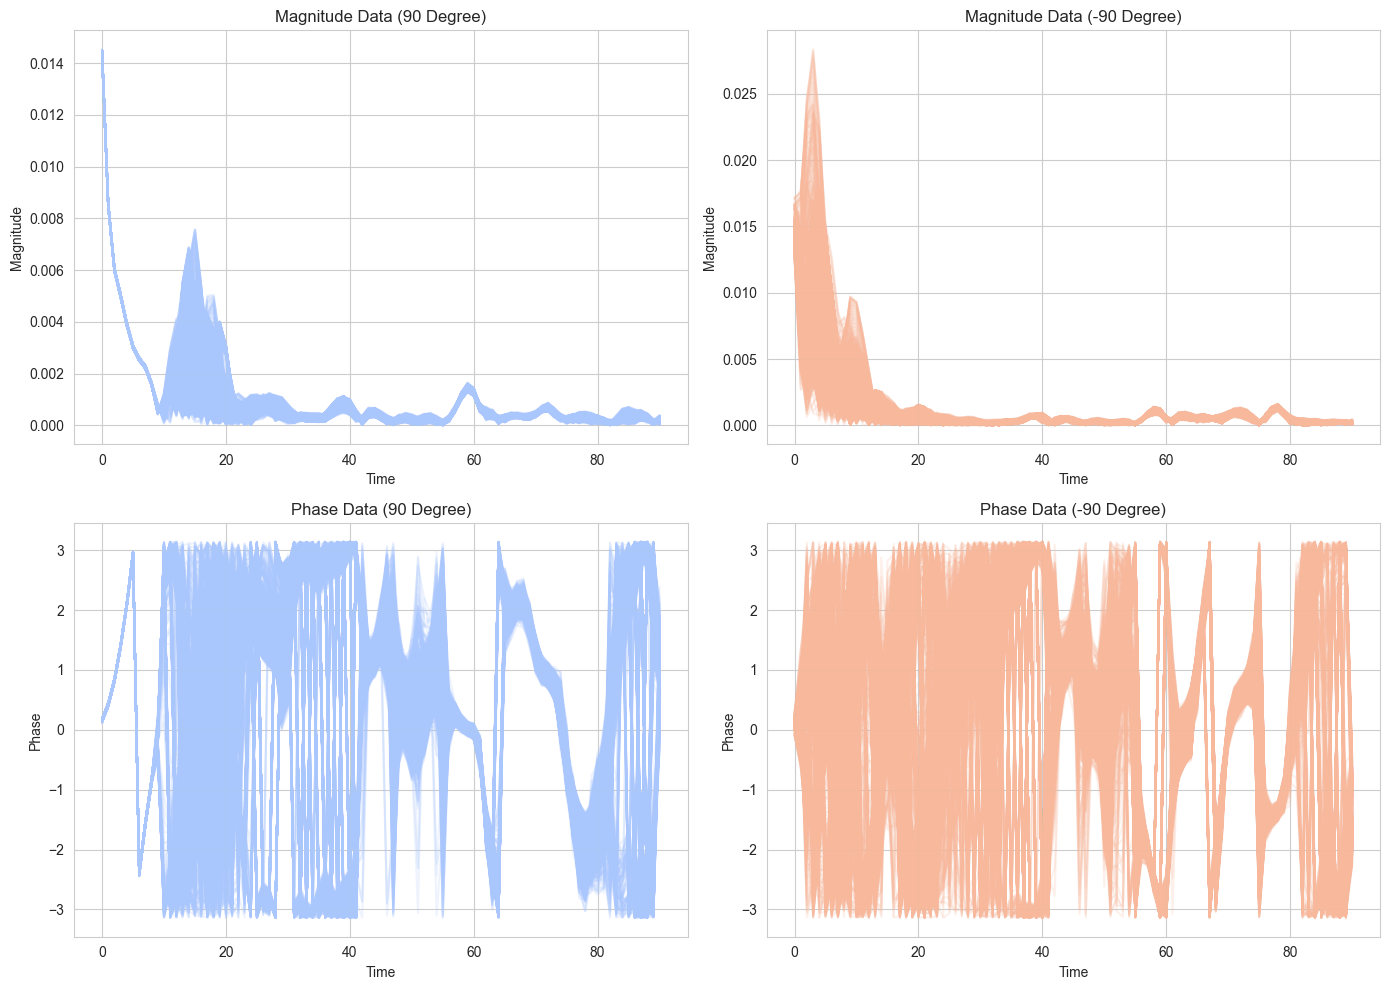

In [5]:

# Load the data as before...
# Setting up a sophisticated color palette and style
sns.set_style("whitegrid")
colors = sns.color_palette("coolwarm", 2)

# Create subplots
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# Plotting magnitude data for 90 degree
for trial in magnitude_data_90:
    ax[0, 0].plot(trial, color=colors[0], alpha=0.2)  # Lighter color for individual trials
ax[0, 0].set_title('Magnitude Data (90 Degree)')
ax[0, 0].set_xlabel('Time')
ax[0, 0].set_ylabel('Magnitude')

# Plotting phase data for 90 degree
for trial in phase_data_90:
    ax[1, 0].plot(trial, color=colors[0], alpha=0.2)  # Lighter color for individual trials
ax[1, 0].set_title('Phase Data (90 Degree)')
ax[1, 0].set_xlabel('Time')
ax[1, 0].set_ylabel('Phase')

# Plotting magnitude data for -90 degree
for trial in magnitude_data_minus90:
    ax[0, 1].plot(trial, color=colors[1], alpha=0.2)  # Lighter color for individual trials
ax[0, 1].set_title('Magnitude Data (-90 Degree)')
ax[0, 1].set_xlabel('Time')
ax[0, 1].set_ylabel('Magnitude')

# Plotting phase data for -90 degree
for trial in phase_data_minus90:
    ax[1, 1].plot(trial, color=colors[1], alpha=0.2)  # Lighter color for individual trials
ax[1, 1].set_title('Phase Data (-90 Degree)')
ax[1, 1].set_xlabel('Time')
ax[1, 1].set_ylabel('Phase')

plt.tight_layout()
plt.show()


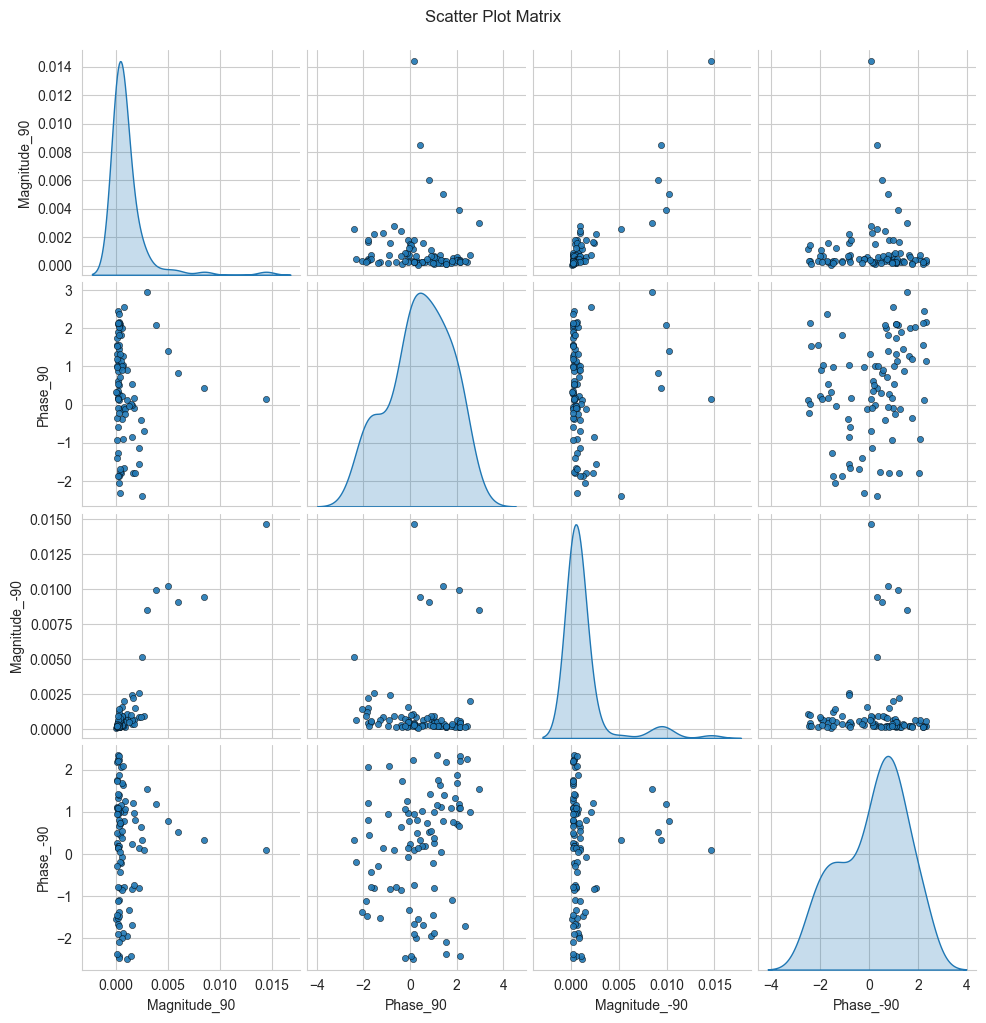

In [7]:
# Prepare data for pairplot
# Using mean as an example. Adjust as needed
df = pd.DataFrame({
    'Magnitude_90': np.mean(magnitude_data_90, axis=0),
    'Phase_90': np.mean(phase_data_90, axis=0),
    'Magnitude_-90': np.mean(magnitude_data_minus90, axis=0),
    'Phase_-90': np.mean(phase_data_minus90, axis=0)
})

# Plotting pairplot
sns.set_style("whitegrid")
sns.pairplot(df, diag_kind='kde', plot_kws={'alpha': 0.9, 's': 20, 'edgecolor': 'k'}, height=2.5)

plt.suptitle("Scatter Plot Matrix", y=1.02)
plt.show()

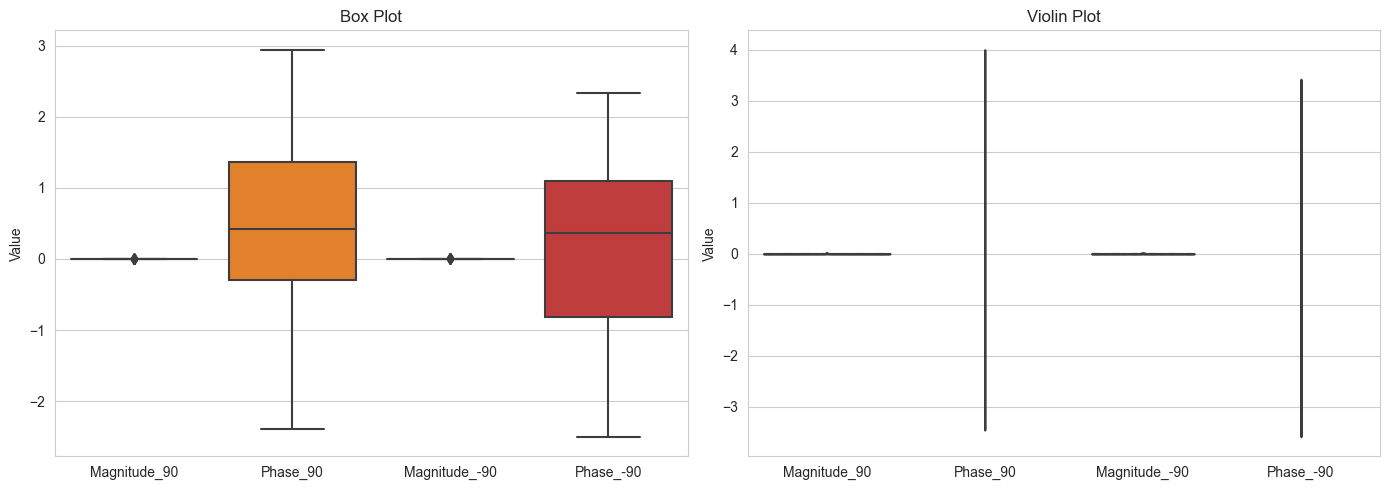

In [8]:
# Prepare data for plots
data = {
    'Magnitude_90': np.mean(magnitude_data_90, axis=0),
    'Phase_90': np.mean(phase_data_90, axis=0),
    'Magnitude_-90': np.mean(magnitude_data_minus90, axis=0),
    'Phase_-90': np.mean(phase_data_minus90, axis=0)
}

# Convert data dictionary to long format for easy plotting with Seaborn
df = pd.DataFrame(data).melt()

# Box and Violin plots
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Box plots
sns.boxplot(x='variable', y='value', data=df, ax=axes[0])
axes[0].set_title('Box Plot')
axes[0].set_ylabel('Value')
axes[0].set_xlabel('')

# Violin plots
sns.violinplot(x='variable', y='value', data=df, ax=axes[1], inner='quartile')
axes[1].set_title('Violin Plot')
axes[1].set_ylabel('Value')
axes[1].set_xlabel('')

# Adjusting layout
plt.tight_layout()
plt.show()

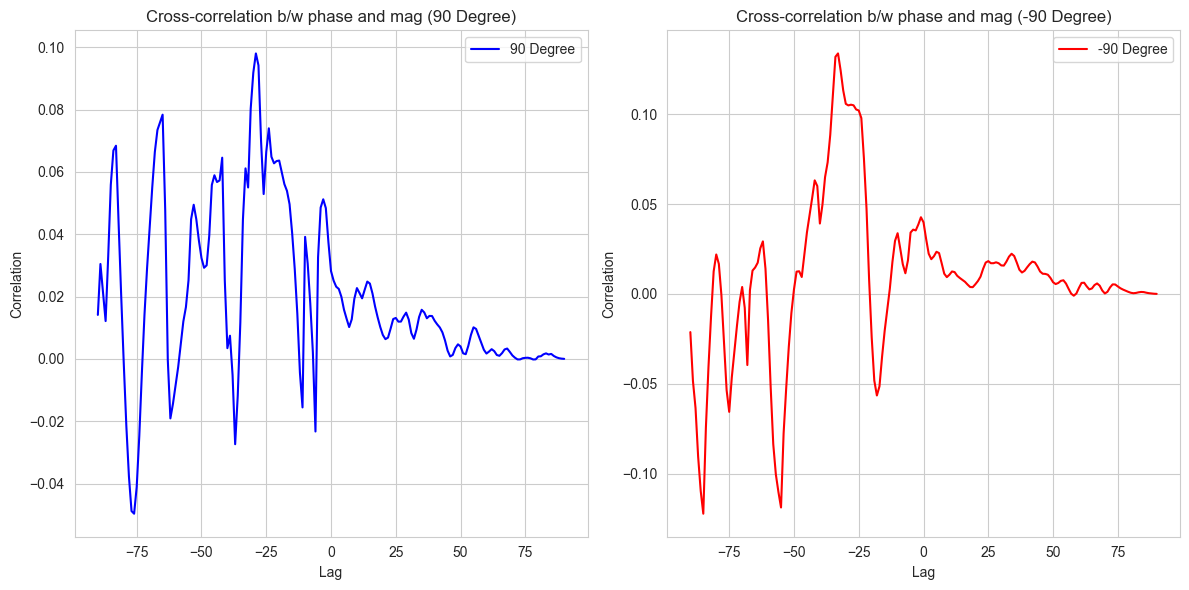

In [9]:
magnitude_90_mean = np.mean(magnitude_data_90, axis=0)
phase_90_mean = np.mean(phase_data_90, axis=0)

magnitude_minus90_mean = np.mean(magnitude_data_minus90, axis=0)
phase_minus90_mean = np.mean(phase_data_minus90, axis=0)

# Calculate cross-correlation
corr_90 = np.correlate(magnitude_90_mean, phase_90_mean, mode='full')
corr_minus90 = np.correlate(magnitude_minus90_mean, phase_minus90_mean, mode='full')

# Define lag values for plotting
lags_90 = np.arange(-len(phase_90_mean) + 1, len(magnitude_90_mean))
lags_minus90 = np.arange(-len(phase_minus90_mean) + 1, len(magnitude_minus90_mean))

# Plotting
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(lags_90, corr_90, label="90 Degree", color="blue")
plt.title('Cross-correlation b/w phase and mag (90 Degree)')
plt.xlabel('Lag')
plt.ylabel('Correlation')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(lags_minus90, corr_minus90, label="-90 Degree", color="red")
plt.title('Cross-correlation b/w phase and mag (-90 Degree)')
plt.xlabel('Lag')
plt.ylabel('Correlation')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

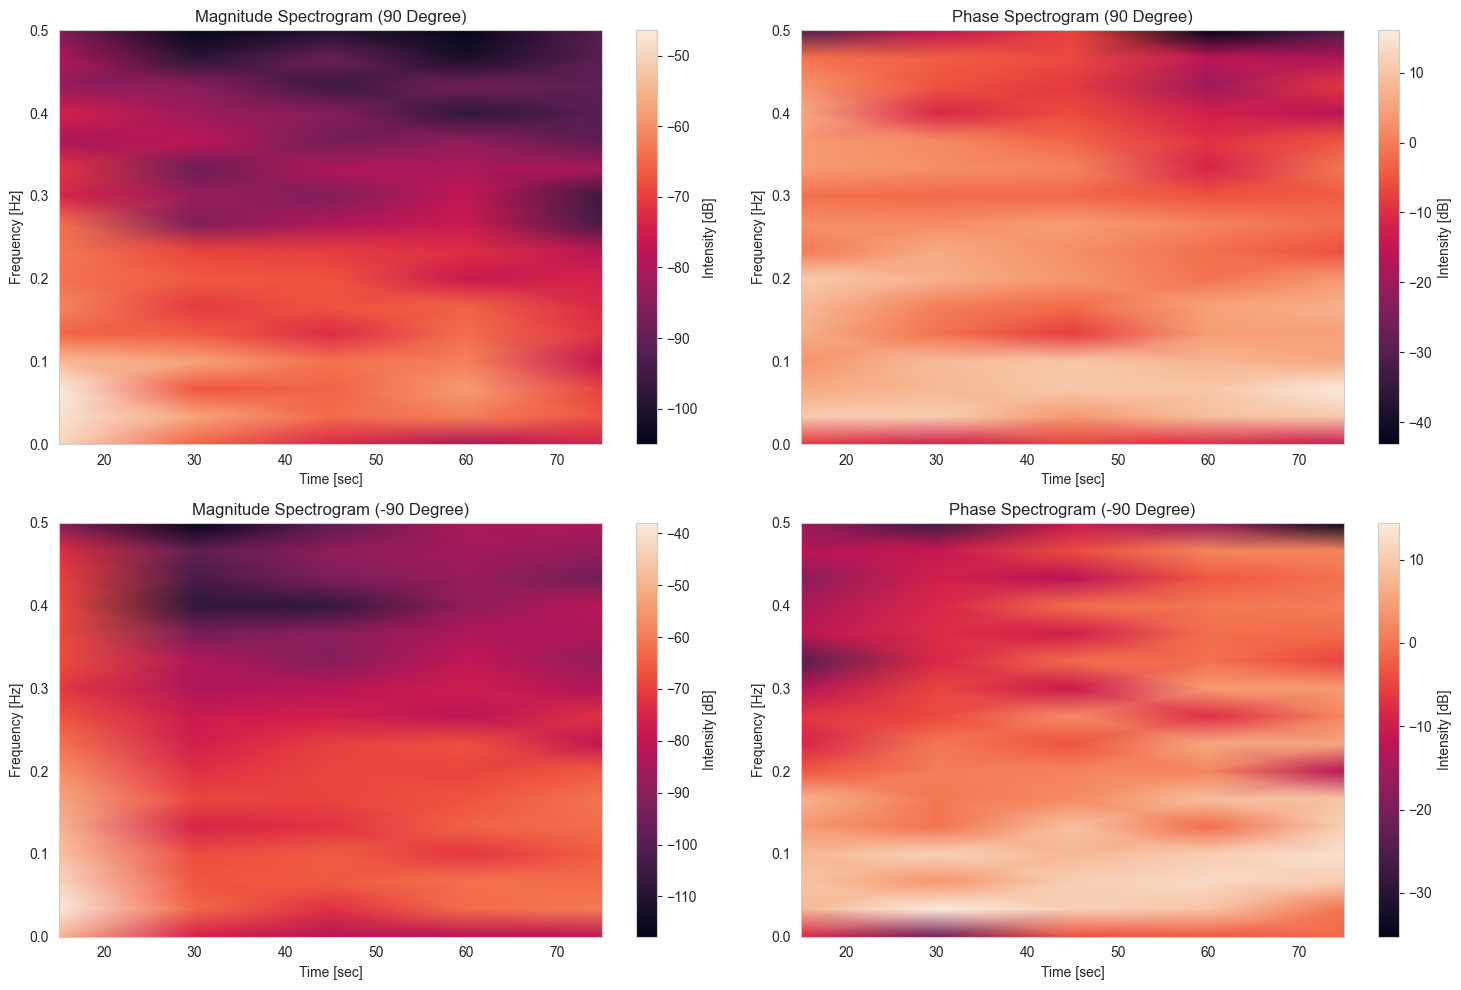

In [6]:
mean_magnitude_90 = np.mean(magnitude_data_90, axis=0)
mean_phase_90 = np.mean(phase_data_90, axis=0)

mean_magnitude_minus90 = np.mean(magnitude_data_minus90, axis=0)
mean_phase_minus90 = np.mean(phase_data_minus90, axis=0)

# Adjusted spectrogram calculations
nperseg_val = 30  # you can experiment with this value
noverlap_val = 15  # typically half of nperseg

# Calculate spectrograms
frequencies_mag_90, times_mag_90, Sxx_mag_90 = spectrogram(mean_magnitude_90, nperseg=nperseg_val, noverlap=noverlap_val)
frequencies_phase_90, times_phase_90, Sxx_phase_90 = spectrogram(mean_phase_90, nperseg=nperseg_val, noverlap=noverlap_val)

frequencies_mag_minus90, times_mag_minus90, Sxx_mag_minus90 = spectrogram(mean_magnitude_minus90, nperseg=nperseg_val, noverlap=noverlap_val)
frequencies_phase_minus90, times_phase_minus90, Sxx_phase_minus90 = spectrogram(mean_phase_minus90, nperseg=nperseg_val, noverlap=noverlap_val)
# Setting up visualization parameters
plt.figure(figsize=(15, 10))

# Plotting
plt.subplot(2, 2, 1)
plt.pcolormesh(times_mag_90, frequencies_mag_90, 10 * np.log10(Sxx_mag_90), shading='gouraud')
plt.colorbar(label='Intensity [dB]')
plt.title('Magnitude Spectrogram (90 Degree)')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')

plt.subplot(2, 2, 2)
plt.pcolormesh(times_phase_90, frequencies_phase_90, 10 * np.log10(Sxx_phase_90), shading='gouraud')
plt.colorbar(label='Intensity [dB]')
plt.title('Phase Spectrogram (90 Degree)')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')

plt.subplot(2, 2, 3)
plt.pcolormesh(times_mag_minus90, frequencies_mag_minus90, 10 * np.log10(Sxx_mag_minus90), shading='gouraud')
plt.colorbar(label='Intensity [dB]')
plt.title('Magnitude Spectrogram (-90 Degree)')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')

plt.subplot(2, 2, 4)
plt.pcolormesh(times_phase_minus90, frequencies_phase_minus90, 10 * np.log10(Sxx_phase_minus90), shading='gouraud')
plt.colorbar(label='Intensity [dB]')
plt.title('Phase Spectrogram (-90 Degree)')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')

# Tight layout for no overlap
plt.tight_layout()
plt.show()